In [1]:
import numpy as np 
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import scipy.linalg
import scipy.spatial
import sympy
from sympy.utilities.lambdify import lambdify

# Introduction to numerical methods

János Török

# Class 5: Derivation

# Differentiation in Python: Symbolic, Numerical and Automatic

## Symbolic Differentiation

Though not used by extremely many, it is worth looking at symbolic calculations

### Symbolic Computation with `SymPy`
One can define variables as symbols:

In [2]:
s = "x y"
x,y = sympy.symbols(s)
print(type(x))

<class 'sympy.core.symbol.Symbol'>


In [3]:
2*x+3

2*x + 3

### Numerical value

In [4]:
(2*x+3).evalf(subs={x:2})

7.00000000000000

### Derivation

In [5]:
sympy.diff(x**3-2*x**2,x)

3*x**2 - 4*x

In [6]:
sympy.diff(x**4-2*x**2,x).evalf(subs={x:2})

24.0000000000000

### Create a `numpy` function out of it

In [7]:
df = lambdify(x, sympy.diff(x**4-2*x**2,x), 'numpy')

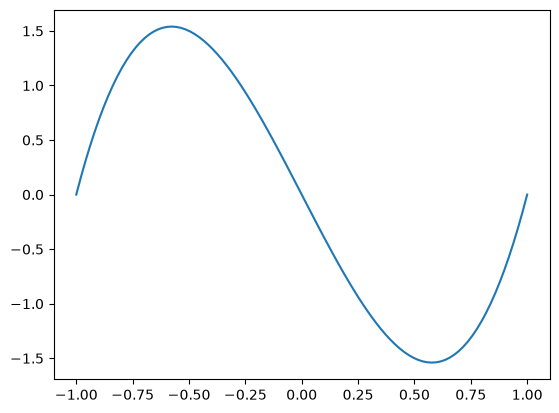

In [8]:
xa = np.linspace(-1,1,100)
plt.plot(xa,df(xa));

In [9]:
sympy.diff(sympy.sin((3*(x+1))**2))

(18*x + 18)*cos((3*x + 3)**2)

## RPN: Reverse Polish Notation

<b>This part is for general information and no test questions will be asked about the RPN notation and the Shunting yard algorithm!</b>

Let us spend some time on how to evaluate a symbolic expression. When we write an expression with parentheses and a strict order of operations, we may ask whether it can be rewritten in a form that is evaluated in one pass, without checking back and forth. The answer is Reverse Polish Notation (RPN).

## RPN: description
The operators always follow their operands. A small example ($\wedge$ is the power operator):
$$\begin{align*}
1+2 \qquad&\to\qquad 1~2~+\\
1+2*3 \qquad&\to\qquad 2~3~*~1~+\\
1*(2+3) \qquad&\to\qquad 1~2~3~+~*\\
\sin\left((3*(x+1))^2\right)\qquad&\to\qquad 3~x~1~+~*~2~\wedge~\sin
\end{align*}
$$

## RPN: evaluation
We process the expression from left to right and use a stack to store intermediate values. A stack is a LIFO (last in, first out) structure: the most recently added item is the first one removed. Each element in the list can be a number, a variable, a unary operator, or a binary operator.

The evaluation steps are:
1. <b>numbers</b>: push the number onto the stack
2. <b>variables</b>: evaluate the variable and push the resulting value onto the stack
3. <b>unary operators</b>: pop the top value, apply the operator, and push the result back
4. <b>binary operators</b>: pop the last two values, apply the operator, and push the result back

Let us look at some examples:


$$ 1+2 \qquad\to\qquad 1~2~+$$
$$
\begin{array}{|l|l|l|}
\hline
\mathbf{index} & \mathbf{RPN} & \mathbf{Stack}\cr
\hline
0 &  \mathbf{1}~2~+ & 1\cr
\hline
1 &  1~\mathbf{2}~+ & 1,2\cr
\hline
2 &  1~2~\mathbf{+} & 3\cr
\hline
\end{array}
$$

$$1+2*3 \qquad\to\qquad 2~3~*~1~+$$
$$
\begin{array}{|l|l|l|}
\hline
\mathbf{index} & \mathbf{RPN} & \mathbf{Stack}\cr
\hline
0 &  \mathbf{2}~3~*~1~+ & 2\cr
\hline
1 &  2~\mathbf{3}~*~1~+  & 2,3\cr
\hline
2 &  2~3~\mathbf{*}~1~+  & 6\cr
\hline
3 &  2~3~*~\mathbf{1}~+  & 6,1\cr
\hline
4 &  2~3~*~1~\mathbf{+}  & 7\cr
\hline
\end{array}
$$

$$1*(2+3) \qquad\to\qquad 1~2~3~+~*$$
$$
\begin{array}{|l|l|l|}
\hline
\mathbf{index} & \mathbf{RPN} & \mathbf{Stack}\cr
\hline
0 &  \mathbf{1}~2~3~+~* & 1\cr
\hline
1 &  1~\mathbf{2}~3~+~*  & 1,2\cr
\hline
2 &  1~2~\mathbf{3}~+~*  & 1,2,3\cr
\hline
3 &  1~2~3~\mathbf{+}~*  & 1,5\cr
\hline
4 &  1~2~3~+~\mathbf{*}  & 5\cr
\hline
\end{array}
$$

$$\sin\left([3*(x+1)]^2\right)\qquad\to\qquad 3~x~1~+~*~2~\wedge~\sin$$

We have to set the value of $x$. Let it be $x=2$.
$$
\begin{array}{|l|l|l|}
\hline
\mathbf{index} & \mathbf{RPN} & \mathbf{Stack}\cr
\hline
0 &  \mathbf{3}~x~1~+~*~2~\wedge~\sin & 3\cr
\hline
1 &  3~\mathbf{x}~1~+~*~2~\wedge~\sin & 3,2\cr
\hline
2 &  3~x~\mathbf{1}~+~*~2~\wedge~\sin & 3,2,1\cr
\hline
3 &  3~x~1~\mathbf{+}~*~2~\wedge~\sin & 3,3\cr
\hline
4 &  3~x~1~+~\mathbf{*}~2~\wedge~\sin & 9\cr
\hline
5 &  3~x~1~+~*~\mathbf{2}~\wedge~\sin & 9,2\cr
\hline
6 &  3~x~1~+~*~2~\mathbf{\wedge}~\sin & 81\cr
\hline
7 &  3~x~1~+~*~2~\wedge~\mathbf{sin} & -0.63\cr
\hline
\end{array}
$$

## RPN: Encoding, the Shunting yard algorithm
Example from Wikipedia: $A+B*C-D$

<img src="Shunting_yard.png">


The input is processed one symbol at a time:
 * If a variable or number is found, it is copied directly to the output a), c), e), h).
 * If the symbol is an operator, it is pushed onto the operator stack b), d), f).
   - If the operator's precedence is lower than that of the operators at the top of the stack
   - If the precedences are equal and the operator is left associative, then that operator is popped off the stack and added to the output g)
 * Finally, any remaining operators are popped off the stack and added to the output i).

$$\sin\left([3*(x+1)]^2\right)$$

Order of the operations: 
 1. $+,-$
 2. $*,/$
 3. $\wedge$
 4. unitary
 5. $(+.-)$
 6. $(*,/)$
 7. $(\wedge)$
 8. unitary
 9. $((+,-))$
 10. etc.
$$
\begin{array}{|l|l|l|}
\hline
\mathbf{Input}& \mathbf{Paranthesis} & \mathbf{Operation~stack(precedence)}  &\mathbf{Output}\cr
\hline
\sin\left([3*(x+1)]\wedge2\right) & 0&  & \cr
\hline
([3*(x+1)]\wedge2) & 0&\sin(4)  & \cr
\hline
[3*(x+1)]\wedge2) & 1&\sin(4)  & \cr
\hline
3*(x+1)]\wedge2) & 2&\sin(4)  & \cr
\hline
*(x+1)]\wedge2) & 2&\sin(4)  & 3\cr
\hline
(x+1)]\wedge2) & 2&\sin(4),*(10)  & 3\cr
\hline
x+1)]\wedge2) & 3&\sin(4),*(10)  & 3\cr
\hline
+1)]\wedge2) & 3&\sin(4),*(10)  & 3,x\cr
\hline
1)]\wedge2) & 3&\sin(4),*(10),+(13)  & 3,x\cr
\hline
)]\wedge2) & 3&\sin(4),*(10),+(13)  & 3,x,1\cr
\hline
]\wedge2) & 2&\sin(4),*(10),+(13)  & 3,x,1\cr
\hline
\wedge2) & 1&\sin(4),*(10),+(13)  & 3,x,1\cr
\hline
2) & 1&\sin(4),\wedge(7) & 3,x,1,+,*\cr
\hline
) & 1&\sin(4),\wedge(7) & 3,x,1,+,*,2\cr
\hline
 & 0& & 3,x,1,+,*,2,\wedge,\sin\cr
\hline
\end{array}
$$

## Derivation?
 * Do it in infix notation
 * In increasing order of operator precedence
 * Implement the formula and recursively call derivation to sub parts, as you would do normally

$$
\begin{align*}
\frac{d}{dx}\sin\left([3*(x+1)]\wedge2\right)&=\cos\left([3*(x+1)]\wedge2\right) * \left([3*(x+1)]\wedge2\right)'=\cr
&=\cos\left([3*(x+1)]\wedge2\right) * 2* [3*(x+1)]*[3*(x+1)]'=\cr
&=\cos(\dots)*2*[3*(x+1)]*[3'*(x+1)+3*(x+1)']=\cr
&=\cos(\dots)*2*[3*(x+1)]*[0*(x+1)+3*(1+0)]
\end{align*}$$

## Numerical derivation

# Finite Difference Approximating Derivatives

The derivative $f'(x)$ of a function $f(x)$ at the point $x=a$ is defined as:

$$f'(a) = \lim\limits_{x \to a}\frac{f(x) - f(a)}{x-a}$$

The derivative at $x=a$ is the slope at this point. In **finite difference** approximations of this slope, we can use values of the function in the neighborhood of the point $x=a$ to achieve the goal. There are various finite difference formulas used in different applications, and three of these, where the derivative is calculated using the values of two points, are presented below. 

The **forward difference** is to estimate the slope of the function at $x_j$ using the line that connects $(x_j, f(x_j))$ and $(x_{j+1}, f(x_{j+1}))$:

$$f'(x_j) = \frac{f(x_{j+1}) - f(x_j)}{x_{j+1}-x_j}$$

The **backward difference** is to estimate the slope of the function at $x_j$ using the line that connects $(x_{j-1}, f(x_{j-1}))$ and $(x_j, f(x_j))$:

$$f'(x_j) = \frac{f(x_j) - f(x_{j-1})}{x_j - x_{j-1}}$$

The **central difference** is to estimate the slope of the function at $x_j$ using the line that connects $(x_{j-1}, f(x_{j-1}))$ and $(x_{j+1}, f(x_{j+1}))$:

$$f'(x_j) = \frac{f(x_{j+1}) - f(x_{j-1})}{x_{j+1} - x_{j-1}}$$

The following figure illustrates the three different type of formulas to estimate the slope. 

<img src="20.02.01-Finite-difference.png" alt="Finite difference" title="Finite difference approximation of the derivative." width="800"/>

## Finite Difference Approximating Derivatives with Taylor Series

To derive an approximation for the derivative of $f$, we return to the Taylor series. For an arbitrary function $f(x)$, the Taylor series of $f$ around $a=x_j$ is
$$
f(x) = \frac{f(x_j)(x - x_j)^0}{0!} + \frac{f^{\prime}(x_j)(x - x_j)^1}{1!} + \frac{f''(x_j)(x - x_j)^2}{2!} + \frac{f'''(x_j)(x - x_j)^3}{3!} + \cdots.
$$

If $x$ is on a grid with spacing $h$, we can evaluate the Taylor series at $x=x_{j+1}$. This gives

$$
f(x_{j+1}) = \frac{f(x_j)(x_{j+1} - x_j)^0}{0!} + \frac{f^{\prime}(x_j)(x_{j+1}- x_j)^1}{1!} + \frac{f''(x_j)(x_{j+1} - x_j)^2}{2!} + \frac{f'''(x_j)(x_{j+1} - x_j)^3}{3!} + \cdots.
$$

Substituting $h=x_{j+1}-x_j$ and solving for $f^{\prime}(x_j)$ gives

$$
f^{\prime}(x_j) = \frac{f(x_{j+1}) - f(x_j)}{h} + \left(-\frac{f''(x_j)h}{2!} -\frac{f'''(x_j)h^2}{3!} - \cdots\right).
$$

The terms in parentheses, $-\frac{f''(x_j)h}{2!} -\frac{f'''(x_j)h^2}{3!} - \cdots$, are called **higher-order terms**. They are grouped together as a remainder term, and the size of this remainder tells us the accuracy of the approximation.


## Higher order derivatives
<img src="secondd1.png">

<img src="secondd2.png">

<img src="secondd3.png">

## Precision
A smaller step size does not always give better accuracy. We must also consider floating-point representation and roundoff error.

In [10]:
def f(x):
    return np.exp(np.sin(2*x))

In [11]:
def fprime(x):
    return 2*np.exp(np.sin(2*x))*np.cos(2*x)

In [12]:
def calc_fd(f,x,h):
    fd = (f(x+h) - f(x))/h
    return fd

In [13]:
def calc_cd(f,x,h):
    cd = (f(x+h/2) - f(x-h/2))/h
    return cd

In [14]:
x0 = 0.5
an = fprime(x0)
hs = [10**(-i) for i in range(1,12)]
fds = [abs(calc_fd(f,x0,h) - an) for h in hs]
cds = [abs(calc_cd(f,x0,h) - an) for h in hs]


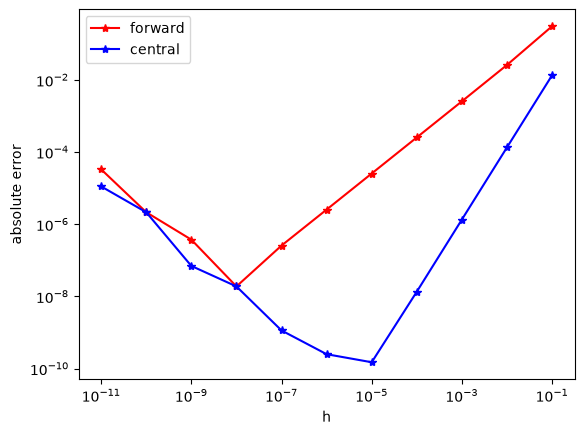

In [15]:
plt.loglog(hs,fds,"r*-",label="forward")
plt.loglog(hs,cds,"b*-",label="central")
plt.xlabel("h")
plt.ylabel("absolute error")
plt.legend();

## Numerical Differentiation with `NumPy`

This method does not require the symbolic expression of the function. The only requirement is that we can evaluate the function at nearby points, such as $x$ and $x+h$, where $h$ is small. Then $$\frac{df}{dx} \approx \frac{f(x+h)-f(x)}{h}$$ is a **numerical approximation** of the derivative.

Different finite-difference formulas use nearby points in different ways, and they trade off speed and accuracy. In all cases, the approximation is not exact because of discretization error and floating-point roundoff. For now, we only need to understand the basic idea and one practical implementation from `NumPy`.

In [16]:
def plot_f1_and_f2(exact, approx, label1="exact", label2="approximate"):
    xs = np.linspace(-5, 5, 100)
    y1 = exact(xs) if callable(exact) else exact
    y2 = approx(xs) if callable(approx) else approx
    plt.figure(figsize=(8, 4))
    plt.plot(xs, y1, label=label1)
    plt.plot(xs, y2, label=label2)
    plt.xlabel("x")
    plt.ylabel("f'(x)")
    plt.legend()
    plt.grid(True)
    plt.show()

x_sym = sympy.symbols('x')
dfdx_symb_numpy = lambdify(x_sym, sympy.diff(x_sym**4 - 2*x_sym**2, x_sym), "numpy")
dfdx_composed = sympy.diff(sympy.sin((3*(x_sym + 1))**2), x_sym)


You can call function `np.gradient` to find the derivative of function $f\left(x\right) = x^2$ defined above. The first argument is an array of function values, the second defines the spacing $\Delta x$ for the evaluation. Here pass it as an array of $x$ values, the differences will be calculated automatically. You can find the documentation [here](https://numpy.org/doc/stable/reference/generated/numpy.gradient.html).

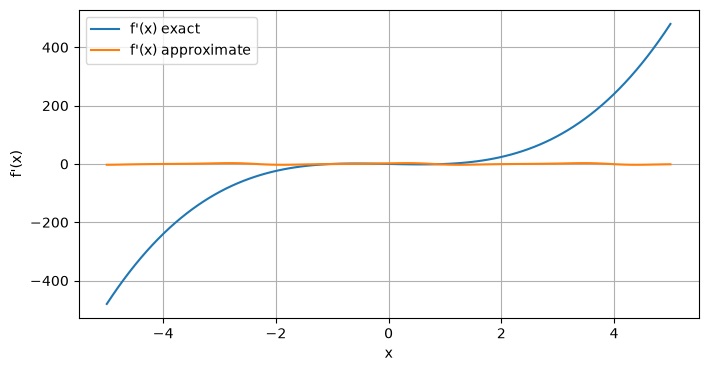

In [17]:
x_array_2 = np.linspace(-5, 5, 100)
dfdx_numerical = np.gradient(f(x_array_2), x_array_2)

plot_f1_and_f2(dfdx_symb_numpy, dfdx_numerical, label1="f'(x) exact", label2="f'(x) approximate")

Try to do numerical differentiation for more complicated function:

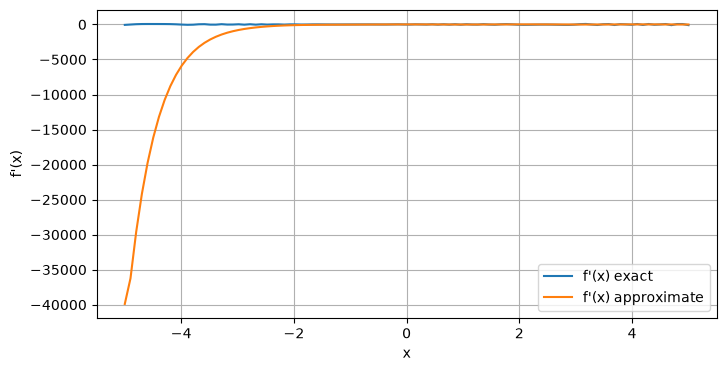

In [18]:
def f_composed(x):
    return np.exp(-2*x) + 3*np.sin(3*x)

plot_f1_and_f2(lambdify(x_sym, dfdx_composed, 'numpy'), np.gradient(f_composed(x_array_2), x_array_2),
              label1="f'(x) exact", label2="f'(x) approximate")


The results are pretty impressive, keeping in mind that it does not matter at all how the function was calculated - only the final values of it!

<a name='3.2'></a>
### 3.2 - Limitations of Numerical Differentiation

Obviously, the first downside of the numerical differentiation is that it is not exact. However, the accuracy of it is normally enough for machine learning applications. At this stage there is no need to evaluate errors of the numerical differentiation.

Another problem is similar to the one which appeared in the symbolic differentiation: it is inaccurate at the points where there are "jumps" of the derivative. Let's compare the exact derivative of the absolute value function and with numerical approximation:

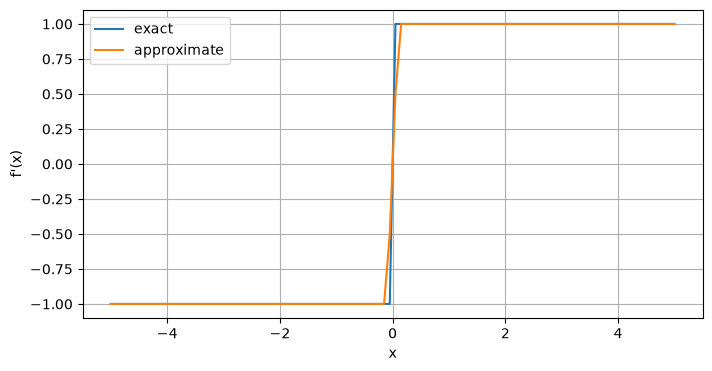

In [19]:
def dfdx_abs(x):
    if x > 0:
        return 1
    else:
        if x < 0:
            return -1
        else:
            return None

plot_f1_and_f2(np.vectorize(dfdx_abs), np.gradient(abs(x_array_2), x_array_2))

You can see that the results near the "jump" are $0.5$ and $-0.5$, while they should be $1$ and $-1$. These cases can give significant errors in the computations.

## Off grid data

In some cases you cannot calculate the function in arbitrary points, but you have a set of arbitrarily placed points in the space with calculated functino values. Can we get the partial derivates along the usual axes?

The answer is yes:
 * For each point select the two closest ones
 * Calculate the gradient with respect to these points
 * Transfer the gradients to the standard basis
Let us see a small example. The potential is $V(\mathbf{r})=r^2$, The gradient $\nabla V =2\mathbf{r}$. For convenience we will always take it at a fixed $z$ value.

In [20]:
def pot(x,y,z):
    return x*x+y*y+z*z
def gradpot(x,y,z):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    z = np.asarray(z, dtype=float)
    return np.array([2*x, 2*y, 2*z*np.ones_like(x)])


### Plot the potential

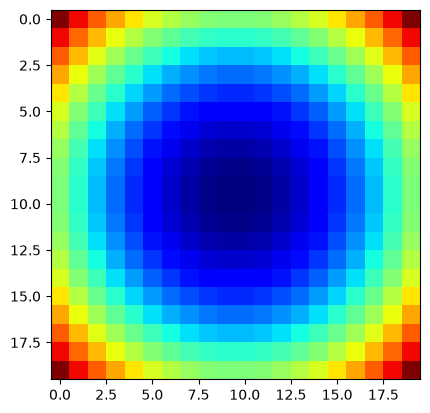

In [21]:
X,Y = np.meshgrid(np.linspace(-1,1,20),np.linspace(-1,1,20))
V = pot(X,Y,0.1)
plt.imshow(V,cmap='jet')

### Plot the gradient at $z=0.1$

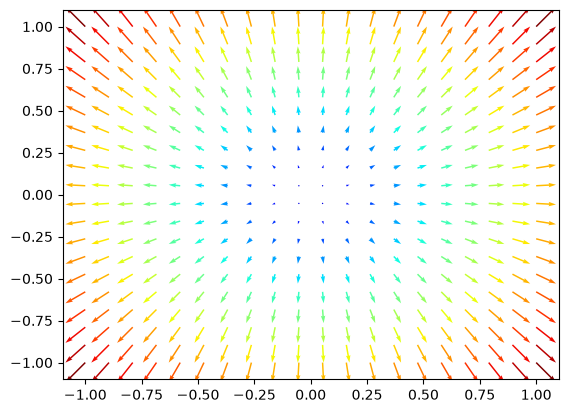

In [22]:
X = X.flatten()
Y = Y.flatten()
graddat=gradpot(X,Y,0.1)
length = np.linalg.norm(graddat,axis=0)/np.linalg.norm(graddat,axis=0).max()
plt.figure()
plt.quiver(X,Y,graddat[0],graddat[1],color=cm.jet(length),scale=50)
plt.show()

### The random $N=1000$ points

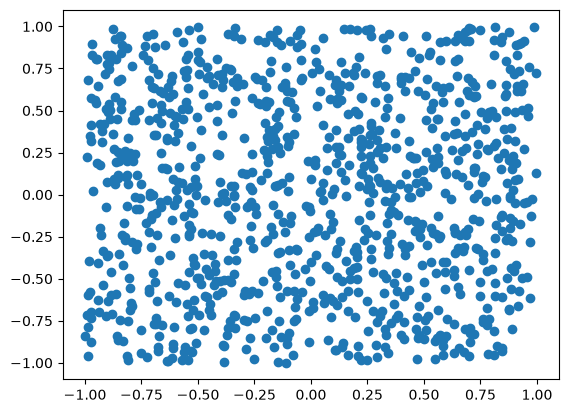

In [23]:
N = 1000
pr = np.random.random((N,2))*2-1
plt.scatter(pr[:,0],pr[:,1])

In [24]:
dm = scipy.spatial.distance_matrix(pr,pr)

C:\Users\nmate\AppData\Local\Temp\ipykernel_24568\1355892263.py:1: DeprecationWarning: `distance_matrix` is deprecated in favor of `scipy.spatial.distance.cdist` as of SciPy 1.18.0 and will be removed in SciPy 1.20.0.
  dm = scipy.spatial.distance_matrix(pr,pr)
C:\Users\nmate\AppData\Local\Temp\ipykernel_24568\1355892263.py:1: DeprecationWarning: `minkowski_distance` is deprecated in favor of `scipy.spatial.distance.minkowski` as of SciPy 1.18.0 and will be removed in SciPy 1.20.0.
  dm = scipy.spatial.distance_matrix(pr,pr)
C:\Users\nmate\AppData\Local\Temp\ipykernel_24568\1355892263.py:1: DeprecationWarning: `minkowski_distance_p` is deprecated in favor of `scipy.spatial.distance.minkowski` as of SciPy 1.18.0 and will be removed in SciPy 1.20.0.
  dm = scipy.spatial.distance_matrix(pr,pr)


### The closest 2 points (we skip the first one as it is the point itself)

In [25]:
dm[5].argsort()[1:3]

array([773, 237])

In [26]:
pr[96]-pr[5]

array([-0.65185306,  0.02430992])

### Calculate the gradient

In [27]:
z = 0.1
grad = np.zeros((N,2),dtype=float)
for i in range(N):
    neighs = dm[i].argsort()[1:3]
    p1 = pr[neighs[0]]
    p2 = pr[neighs[1]]
    poti = pot(pr[i][0],pr[i][1],z)
    pot1 = pot(p1[0],p1[1],z)
    pot2 = pot(p2[0],p2[1],z)
    dp1 = p1 - pr[i]
    dp2 = p2 - pr[i]
    d1 = pot1 - poti
    d2 = pot2 - poti
    A = np.vstack([dp1,dp2])
    grad[i] = np.dot(np.linalg.inv(A),[d1,d2])

### Plot the gradient at the given points

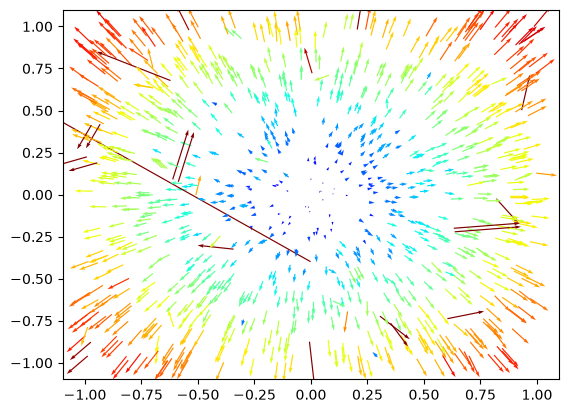

In [28]:
length = np.linalg.norm(grad,axis=1)/np.linalg.norm(graddat,axis=0).max()
plt.figure()
plt.quiver(pr[:,0],pr[:,1],grad[:,0],grad[:,1],color=cm.jet(length),scale=50)
plt.show()

### Observations
 * In general the results are acceptable
 * Large errors due to marginally linearly indepependent vectors

In [29]:
z = 0.1
grad = np.zeros((N,2),dtype=float)
for i in range(N):
    neighs = dm[i].argsort()[1:3]
    p1 = pr[neighs[0]]
    p2 = pr[neighs[1]]
    poti = pot(pr[i][0],pr[i][1],z)
    pot1 = pot(p1[0],p1[1],z)
    pot2 = pot(p2[0],p2[1],z)
    dp1 = p1 - pr[i]
    dp2 = p2 - pr[i]
    d1 = pot1 - poti
    d2 = pot2 - poti
    A = np.vstack([dp1,dp2])
    grad[i] = np.dot(np.linalg.inv(A),[d1,d2])
    if np.linalg.norm(grad[i]-gradpot(pr[i,0],pr[i,1],z)[:2]) > 1.5:
        cross_val = dp1[0]*dp2[1] - dp1[1]*dp2[0]
        print(cross_val/np.linalg.norm(dp1)/np.linalg.norm(dp2),
              np.linalg.norm(grad[i]-gradpot(pr[i,0],pr[i,1],z)[:2]))


0.02115615779688465 2.769203885866445
-0.028922253205692028 6.31914330889397
-0.03789824478367953 2.6034102057014255
0.042666297068941865 2.555501406284405
-0.0005591133502467903 173.77754926670696
0.005385307740385129 5.4952097568460365
0.01057410950655888 6.404040028571752
0.003319372128773773 5.589808982764506
0.03197984929536994 3.3429261009957307
-0.010860760745551914 1.5586088611605835
0.035588150493400486 3.1175927672044326
-0.04801914538932106 1.558608861160618
0.0014623252834249573 5.495209756845928
-0.03774208957772818 2.6759745106788966
-0.02750277653797117 2.5489999808523702
-0.04058932311350989 2.51847942882166
-0.03761931194694303 3.3636948968588465
-0.01674293298957408 3.3037781326274813
-0.0048948646765708285 3.303778132627489
0.008429454764161043 5.589808982764514


In [30]:
z = 0.1
grad = np.zeros((N,2),dtype=float)
for i in range(N):
    neighs = dm[i].argsort()[1:3]
    p1 = pr[neighs[0]]
    p2 = pr[neighs[1]]
    poti = pot(pr[i][0],pr[i][1],z)
    pot1 = pot(p1[0],p1[1],z)
    pot2 = pot(p2[0],p2[1],z)
    dp1 = p1 - pr[i]
    dp2 = p2 - pr[i]
    d1 = pot1 - poti
    d2 = pot2 - poti
    A = np.vstack([dp1,dp2])
    grad[i] = np.dot(np.linalg.inv(A),[d1,d2])
    cross_val = dp1[0]*dp2[1] - dp1[1]*dp2[0]
    if abs(cross_val/np.linalg.norm(dp1)/np.linalg.norm(dp2)) < 0.02:
        print(cross_val/np.linalg.norm(dp1)/np.linalg.norm(dp2),
              np.linalg.norm(grad[i]-gradpot(pr[i,0],pr[i,1],z)[:2]))


0.019380608991229408 0.22060417532368254
-0.0005591133502467903 173.77754926670696
0.014371419901696068 0.7706474365181938
0.005385307740385129 5.4952097568460365
0.01057410950655888 6.404040028571752
0.003319372128773773 5.589808982764506
-0.010860760745551914 1.5586088611605835
0.0014623252834249573 5.495209756845928
-0.01611524161837941 0.7706474365181833
-0.01674293298957408 3.3037781326274813
-0.0048948646765708285 3.303778132627489
0.008429454764161043 5.589808982764514
